In [1]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.cross_decomposition import CCA


from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Desktop/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
dims = 2
dims_preca = 5

# read_ids = list(range(0, 12+1))
# read_ids = [0,   # paper
# 			2,
# 			3,
# 			4,
# 			5,
# 			6,
# 			8,
# 			9]   # good
read_ids = [0]
plot_id = 0

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

/home/julian-zim/Desktop/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/utils_fly/read_utils.py:58: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  data = pickle.load(file)


In [5]:
# prep

def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

In [6]:
selection_bhl = ['walk', 'still', 'front-groom', 'back-groom', 'abdomen-move', 'background']

plot_idx = file_ids.index(plot_id)

# states = [s[selection_bhl] for s in states]

# manifold

In [7]:
# correlations = [trace.corr() for trace in traces]
#
# # plot
# heatmap = sns.clustermap(correlations[plot_idx], yticklabels=True, xticklabels=True)
# heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
# heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
# heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)
#
# plt.title(filenames[plot_idx], fontsize=8, y=1.05)
# plt.show()

In [8]:
# (modes_manifold, modes_manifold_b,
#  recos_manifold, recos_manifold_b,
#  loads_cca_man, loads_cca_man_b,
#  vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
# 																	[s[selection_bhl] for s in states],
# 																	n_cv=dims, n_pc=dims_preca)

(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, zscore=False,
												 n_pc=dims)

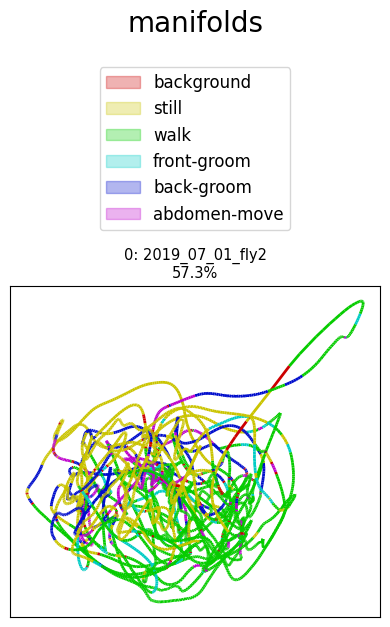

57.3%


In [9]:
# plot
plot_utils.plot_manifolds(
	[f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
	modes_manifold, states,
	vars_expl_mans, None,
	top_space=2.5)

In [10]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :]) for xloads_pca_man in loads_pca_man]

traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]
traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]

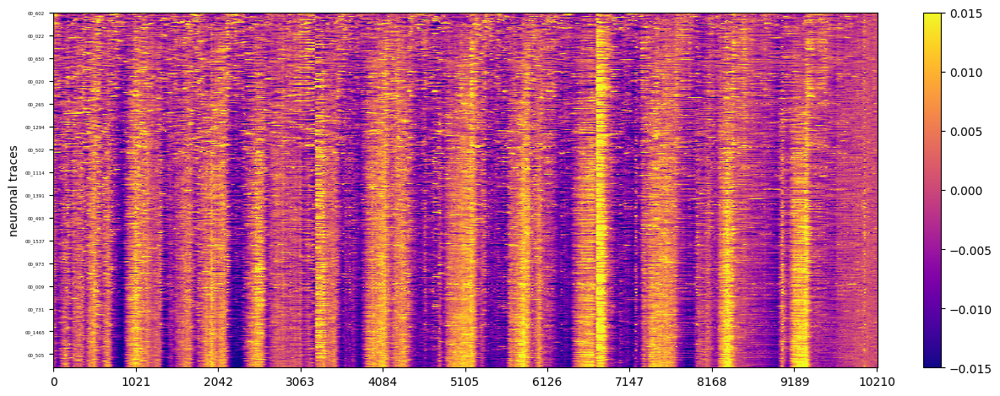

In [11]:
# plot
plot_utils.plot_heatmap_stack(
	traces_sorted[plot_idx],
	None,
	'neuronal traces', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

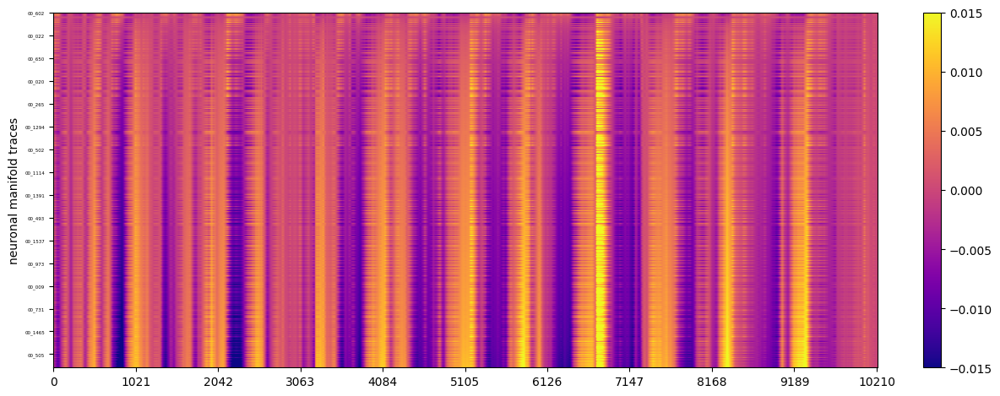

In [12]:
# plot
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[plot_idx],
	None,
	'neuronal manifold traces', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

# concrete behavior

In [13]:
traces_residuals = [pd.DataFrame(data=t.values - t_man.values, columns=t.columns) for t, t_man in zip(traces, recos_manifold)]

traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]

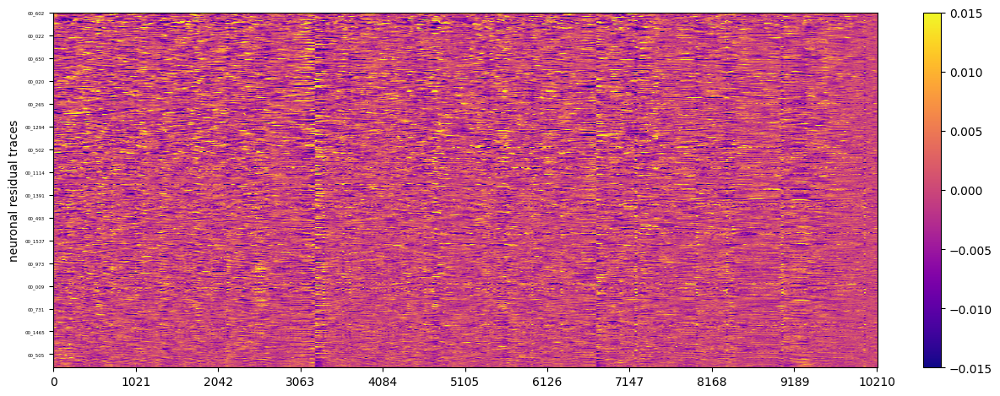

In [14]:
# plot
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[plot_idx],
	None,
	'neuronal residual traces', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

In [15]:
# correlations_residuals = [trace_res.corr() for trace_res in traces_residuals]
#
# # plot
# heatmap = sns.clustermap(correlations_residuals[plot_idx], xticklabels=True, yticklabels=True)
# heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
# heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
# heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)
#
# plt.title(filenames[plot_idx], fontsize=8, y=1.05)
# plt.show()

In [58]:
markers_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers
]

n = markers[plot_idx].values.shape[1]

modes_concrete = list()
recos_concrete = list()
loads_cca_con, loads_cca_con_b = list(), list()
vars_expl_con, vars_expl_con_rs = list(), list()  # rs in this case: variance explained with respect to the residual data
for trace, trace_residual, marker in zip(traces, traces_residuals, markers):
	cca = CCA(n_components=n, scale=True)

	trace_residual_reduced, marker_reduced = cca.fit_transform(trace_residual.values, marker.values)
	trace_residual_reconstructed, marker_reconstructed = cca.inverse_transform(trace_residual_reduced, marker_reduced)

	modes_concrete.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CV{i + 1}' for i in range(n)]))
	recos_concrete.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	loads_cca_con.append(cca.x_loadings_)
	loads_cca_con_b.append(cca.y_loadings_)

	var_ratio = train_utils.get_variance_explained(trace_residual_reconstructed, trace)
	var_ratio_rs = train_utils.get_variance_explained(trace_residual_reconstructed, trace_residual)
	vars_expl_con.append([var_ratio])
	vars_expl_con_rs.append([var_ratio_rs])

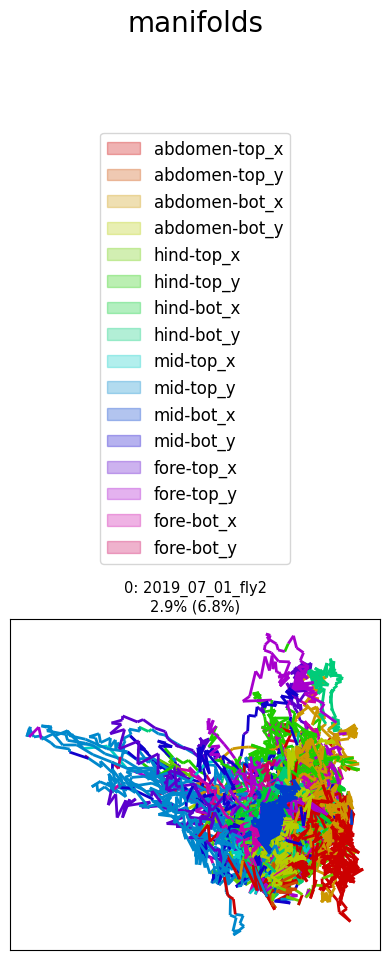

2.9% (6.8%)


In [39]:
# plot
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_concrete, markers_zs,
						  vars_expl_con, vars_expl_con_rs,
						  top_space=6.5)

In [40]:
traces_concretes_indices = [np.argsort(xloads_cca_con[:, 0]) for xloads_cca_con in loads_cca_con]
markers_indices = [np.argsort(yloads_cca_con[:, 0])[::-1] for yloads_cca_con in loads_cca_con_b]

markers_sorted = [marker.iloc[:, marker_idx.tolist()] for marker, marker_idx in zip(markers_zs, markers_indices)]
traces_concretes_sorted = [t_con.iloc[:, t_con_idx.tolist()] for t_con, t_con_idx in zip(recos_concrete, traces_concretes_indices)]

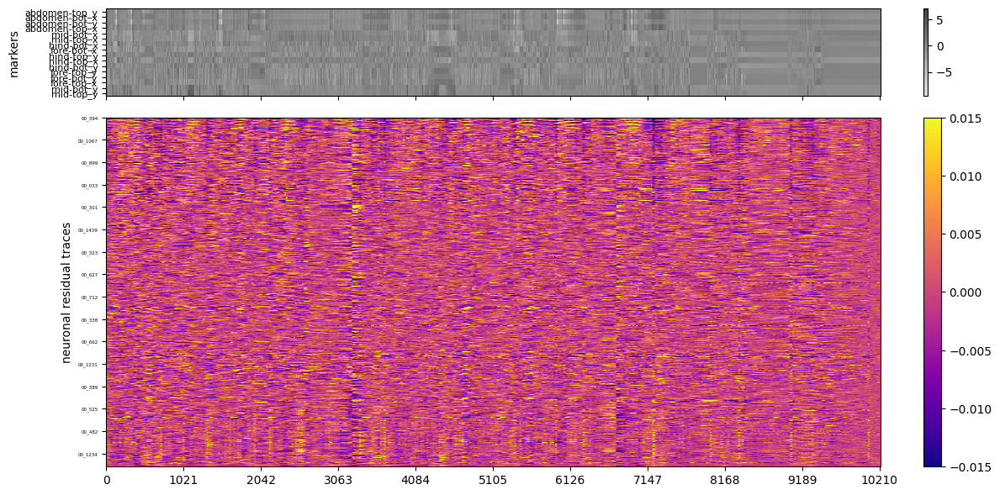

In [41]:
traces_residuals_sorted_by_concretes = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_concretes_indices)]

# plot
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_concretes[plot_idx],
	markers_sorted[plot_idx],
	'neuronal residual traces', 'markers',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

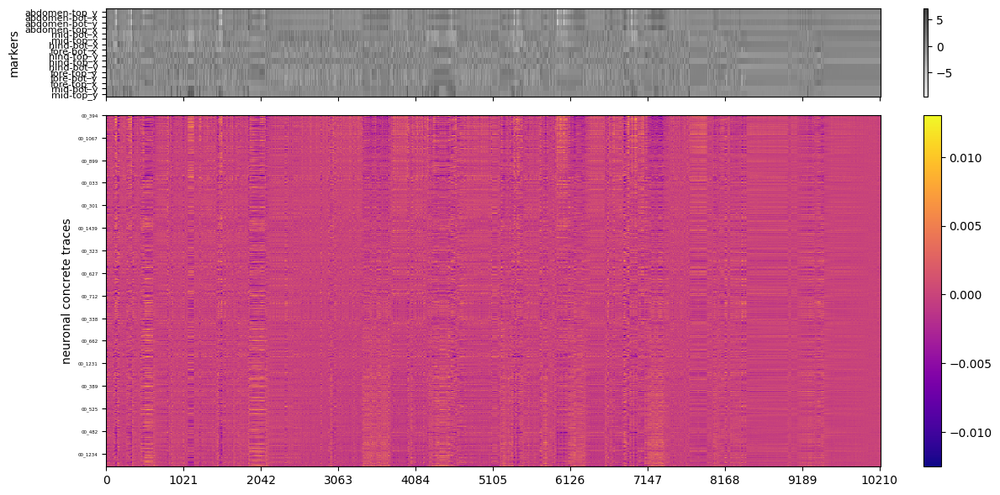

In [42]:
# plot
plot_utils.plot_heatmap_stack(
	traces_concretes_sorted[plot_idx],
	markers_sorted[plot_idx],
	'neuronal concrete traces', 'markers',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

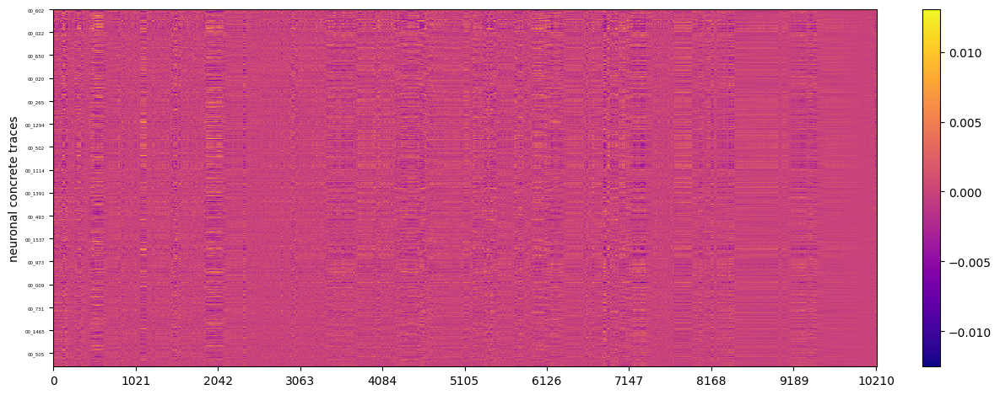

In [43]:
traces_concretes_sorted_by_manifold = [t_con.iloc[:, t_man_idx.tolist()] for t_con, t_man_idx in zip(recos_concrete, traces_manifolds_indices)]

# plot
plot_utils.plot_heatmap_stack(
	traces_concretes_sorted_by_manifold[plot_idx],
	None,
	'neuronal concrete traces', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

# other

In [44]:
traces_others = [pd.DataFrame(data=t_res.values - t_con.values, columns=t_res.columns) for t_res, t_con in zip(traces_residuals, recos_concrete)]

traces_others_sorted_by_concretes = [t_oth.iloc[:, t_con_idx.tolist()] for t_oth, t_con_idx in zip(traces_others, traces_concretes_indices)]

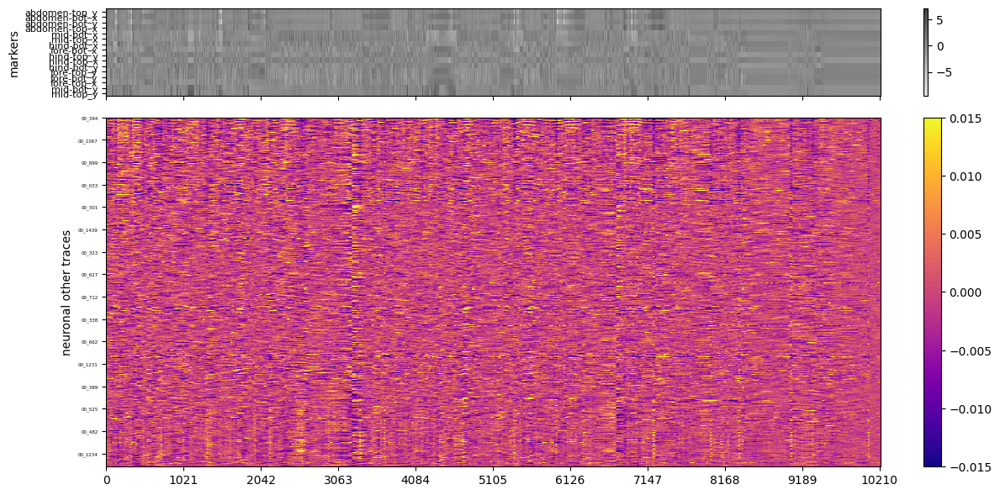

In [45]:
# plot
plot_utils.plot_heatmap_stack(
	traces_others_sorted_by_concretes[plot_idx],
	markers_sorted[plot_idx],
	'neuronal other traces', 'markers',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

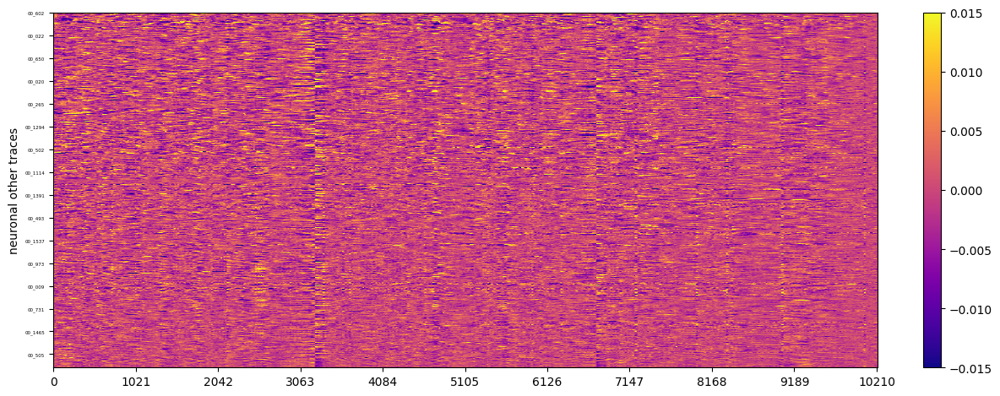

In [46]:
traces_others_sorted_by_manifold = [t_oth.iloc[:, t_man_idx.tolist()] for t_oth, t_man_idx in zip(traces_others, traces_manifolds_indices)]

# plot
plot_utils.plot_heatmap_stack(
	traces_others_sorted_by_manifold[plot_idx],
	None,
	'neuronal other traces', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

# total reconstruction error

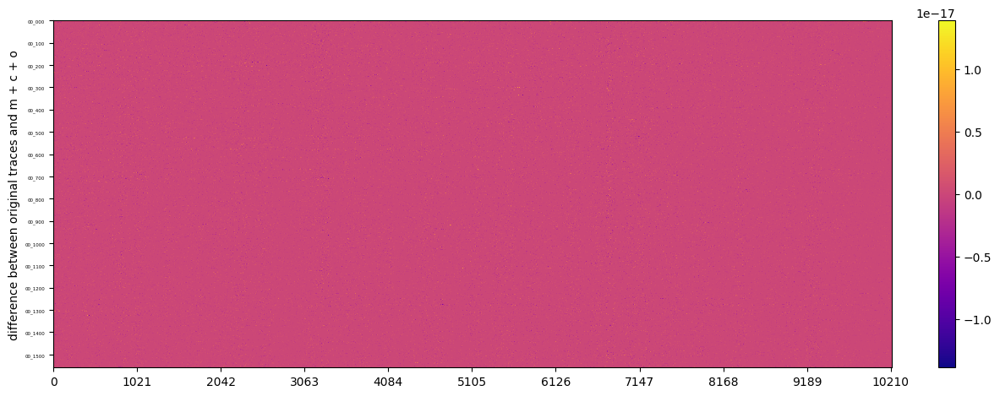

In [47]:
traces_diff = [pd.DataFrame(data=t.values - (t_man.values + t_con.values + t_oth.values), columns=t.columns) for t, t_man, t_con, t_oth in zip(traces, recos_manifold, recos_concrete, traces_others)]

# plot
plot_utils.plot_heatmap_stack(
	traces_diff[plot_idx],
	None,
	'difference between original traces and m + c + o', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

# variances explained per neuron per dataset

In [48]:
mcos_full = list()
mco_ratios_full = list()
for i in range(len(filenames)):

	traces_all_var = np.var(traces[i].values, axis=0)
	traces_res_var = np.var(traces_residuals[i].values, axis=0)
	traces_man_var = traces_all_var - traces_res_var
	traces_oth_var = np.var(traces_others[i].values, axis=0)
	traces_con_var = traces_res_var - traces_oth_var
	mco = pd.DataFrame(data=np.vstack([traces_all_var, traces_man_var, traces_res_var, traces_con_var, traces_oth_var]),
					   columns=traces[i].columns,
					   index=['a', 'm', 'r', 'c', 'o'])
	mcos_full.append(mco)

	traces_all_var_ratio = traces_all_var / traces_all_var
	traces_res_var_ratio = traces_res_var / traces_all_var
	traces_man_var_ratio = traces_man_var / traces_all_var
	traces_oth_var_ratio = traces_oth_var / traces_all_var
	traces_con_var_ratio = traces_con_var / traces_all_var
	mco_ratio = pd.DataFrame(data=np.vstack([traces_all_var_ratio, traces_man_var_ratio, traces_res_var_ratio, traces_con_var_ratio, traces_oth_var_ratio]),
							 columns=traces[i].columns,
							 index=['a', 'm', 'r', 'c', 'o'])
	mco_ratios_full.append(mco_ratio)


neurons_labels = [traces[i].columns for i in range(len(filenames))]
unique_labels_full = sorted(list(set([l for label in neurons_labels for l in label])))
unique_labels = [label for label in unique_labels_full if label != '' and label[-1] != '_']

mcos = list()
for mco in mcos_full:
	mco_filtered = mco[sorted(list(set(unique_labels) & set(mco.columns)))]
	if len(mco_filtered.columns) > 0:
		mcos.append(mco_filtered)
mco_ratios = list()
for mco_ratio in mco_ratios_full:
	mco_ratio_filtered = mco_ratio[sorted(list(set(unique_labels) & set(mco_ratio.columns)))]
	if len(mco_ratio_filtered.columns) > 0:
		mco_ratios.append(mco_ratio_filtered)

# variances explained per neuron averaged over datasets

In [49]:
mcos_avg = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
mcos_std = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
for neuron in unique_labels:
	amrco = {'a': [], 'm': [], 'r': [], 'c': [], 'o': []}
	for mco in mcos:
		if neuron in mco.columns:
			for key in amrco.keys():
				amrco[key].append(mco[neuron][key])
	mcos_avg[neuron] = [np.mean(np.array(amrco[key])) for key in amrco.keys()]
	mcos_std[neuron] = [np.std(np.array(amrco[key])) for key in amrco.keys()]

In [50]:
mco_ratios_avg = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
mco_ratios_std = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
for neuron in unique_labels:
	amrco_ratio = {'a': [], 'm': [], 'r': [], 'c': [], 'o': []}
	for mco_ratio in mco_ratios:
		if neuron in mco_ratio.columns:
			for key in amrco_ratio.keys():
				amrco_ratio[key].append(mco_ratio[neuron][key])
	mco_ratios_avg[neuron] = [np.mean(np.array(amrco_ratio[key])) for key in amrco_ratio.keys()]
	mco_ratios_std[neuron] = [np.std(np.array(amrco_ratio[key])) for key in amrco_ratio.keys()]

# M-C-O ratio bar plots

Average m: 55.1%
Average c: 3.1%
Average o: 41.7%


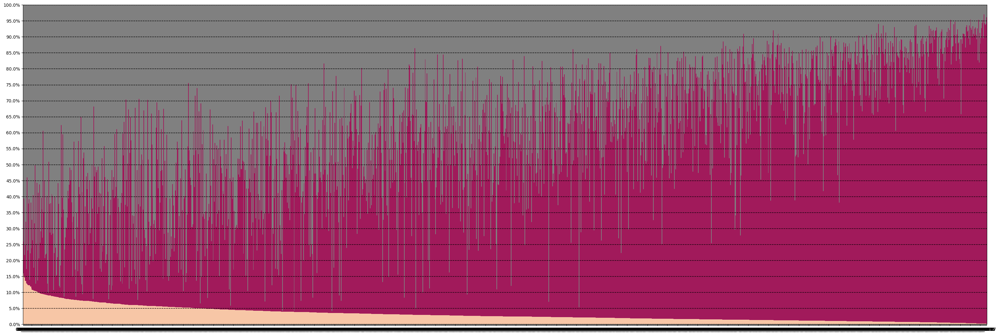

In [51]:
mco_ratio_c_avg = mco_ratios_avg.T[['m', 'c', 'o']].sort_values(by='c', ascending=False).T
mco_ratio_c_std = mco_ratios_std.T[['m', 'c', 'o']].reindex(mco_ratio_c_avg.T.index).T

importlib.reload(plot_utils)
# plot
plot_utils.plot_mcos(mco_ratio_c_avg, mco_ratio_c_avg.columns,
					 None,
					 order=('c', 'm', 'o'))

Average m: 55.1%
Average c: 3.1%
Average o: 41.7%


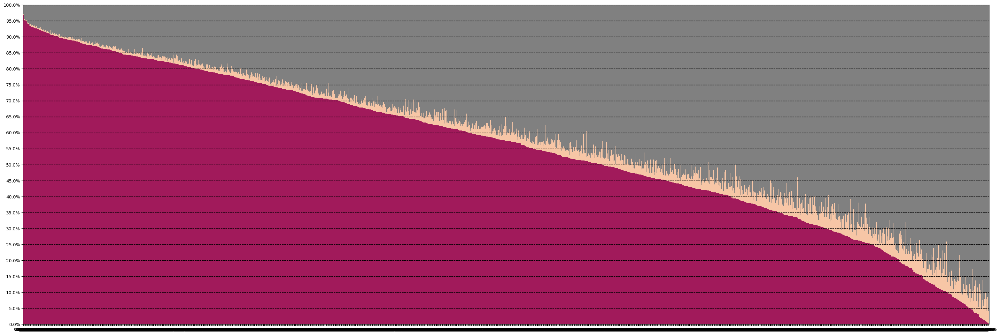

In [52]:
mco_ratio_m_avg = mco_ratios_avg.T[['m', 'c', 'o']].sort_values(by='m', ascending=False).T
mco_ratio_m_std = mco_ratios_std.T[['m', 'c', 'o']].reindex(mco_ratio_m_avg.T.index).T

# plot
plot_utils.plot_mcos(mco_ratio_m_avg, mco_ratio_m_avg.columns,
					 None,
					 order=('m', 'c', 'o'))

Average m: 55.1%
Average c: 3.1%
Average o: 41.7%


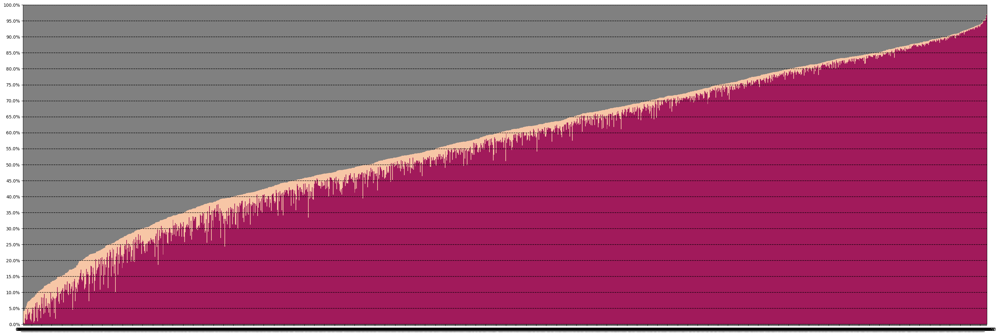

In [53]:
mco_ratio_o_avg = mco_ratios_avg.T[['m', 'c', 'o']].sort_values(by='o', ascending=False).T
mco_ratio_o_std = mco_ratios_std.T[['m', 'c', 'o']].reindex(mco_ratio_o_avg.T.index).T

# plot
plot_utils.plot_mcos(mco_ratio_o_avg, mco_ratio_o_avg.columns,
					 None,
					 order=('m', 'c', 'o'))

# M-C-O bar plots

Average m: 0.0%
Average c: 0.0%
Average o: 0.0%


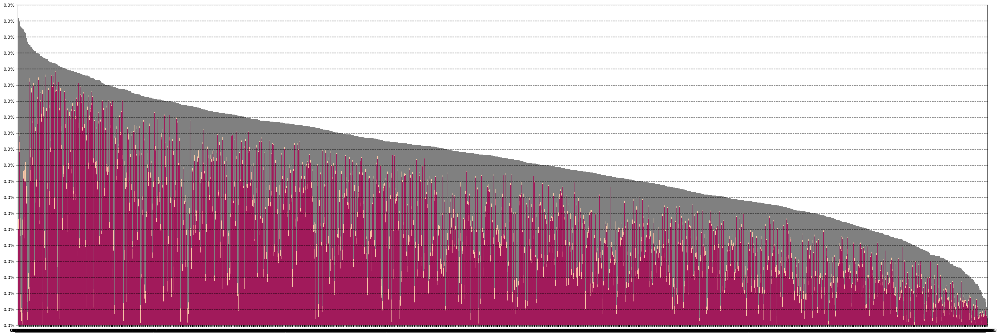

In [54]:
mco_m_avg = mcos_avg.T.sort_values(by='a', ascending=False)[['m', 'c', 'o']].T
mco_m_std = mcos_std.T.reindex(mco_m_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_m_avg, mco_m_avg.columns,
					 None,
					 order=('m', 'c', 'o'),
					 normalized=False)

Average m: 0.0%
Average c: 0.0%
Average o: 0.0%


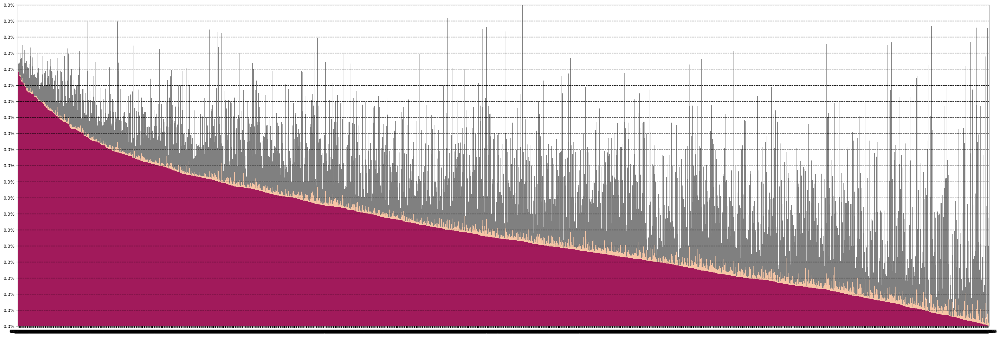

In [55]:
mco_m_avg = mcos_avg.T.sort_values(by='m', ascending=False)[['m', 'c', 'o']].T
mco_m_std = mcos_std.T.reindex(mco_m_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_m_avg, mco_m_avg.columns,
					 None,
					 order=('m', 'c', 'o'),
					 normalized=False)

Average m: 0.0%
Average c: 0.0%
Average o: 0.0%


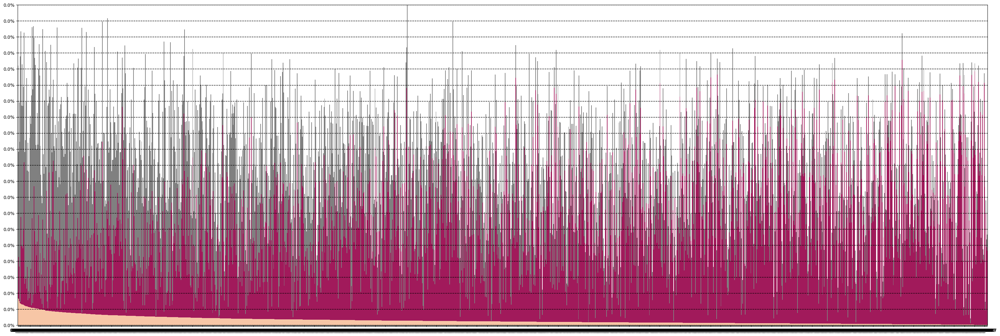

In [56]:
mco_c_avg = mcos_avg.T.sort_values(by='c', ascending=False)[['m', 'c', 'o']].T
mco_c_std = mcos_std.T.reindex(mco_c_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_c_avg, mco_c_avg.columns,
					 None,
					 order=('c', 'm', 'o'),
					 normalized=False)

Average m: 0.0%
Average c: 0.0%
Average o: 0.0%


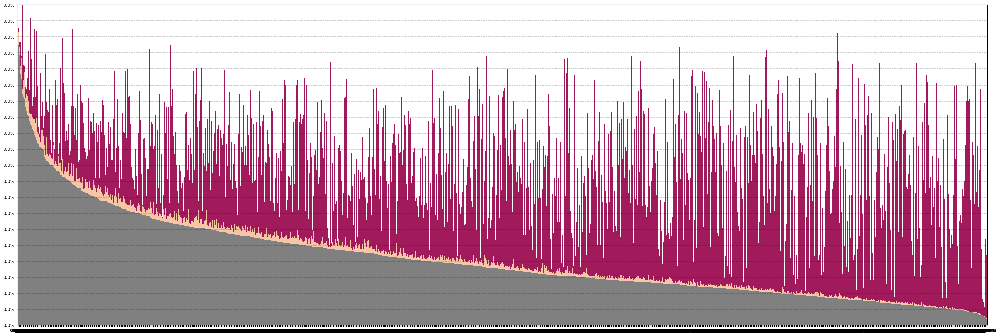

In [57]:
mco_o_avg = mcos_avg.T.sort_values(by='o', ascending=False)[['m', 'c', 'o']].T
mco_o_std = mcos_std.T.reindex(mco_o_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_o_avg, mco_o_avg.columns,
					 None,
					 order=('o', 'c', 'm'),
					 normalized=False)